--> Loading Text Dataset...
Dataset successfully loaded. Shape: (5572, 3)

First 5 Records:
  label                                            message  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

--> Preprocessing text messages...
TF-IDF Feature Space Dimensions: 5000 terms

--- Model Benchmark Performance ---
                           Model  Accuracy  Precision (Spam)  Recall (Spam)  F1-Score (Spam)  5-Fold CV F1
Linear Support Vector Classifier  0.983857          0.971223       0.906040         0.937500      0.920781
         Multinomial Naive Bayes  0.978475          0.962963       0.872483   

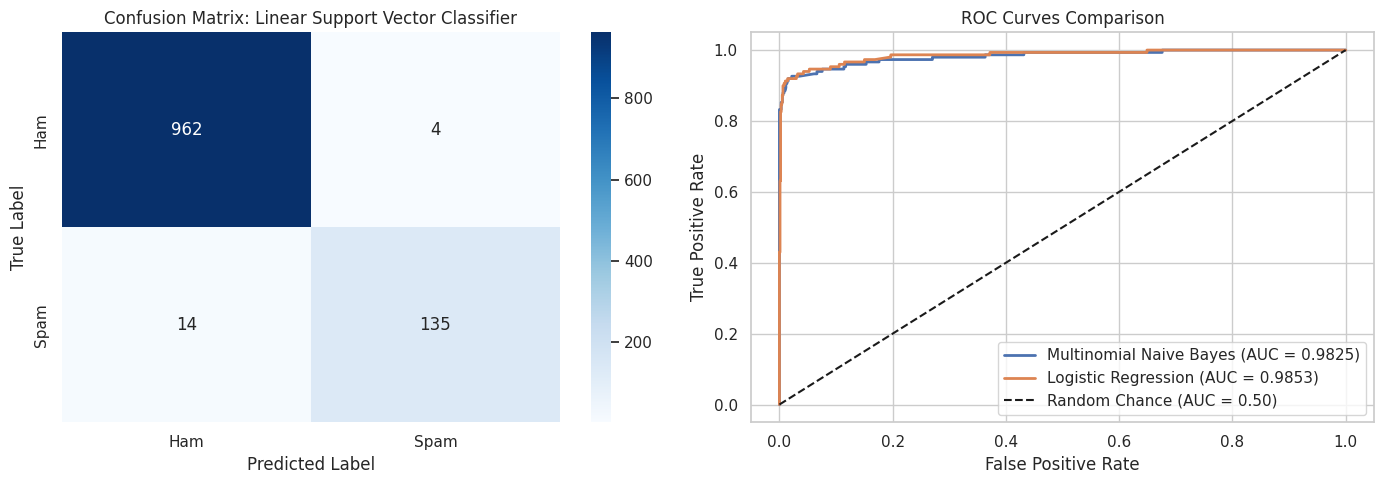

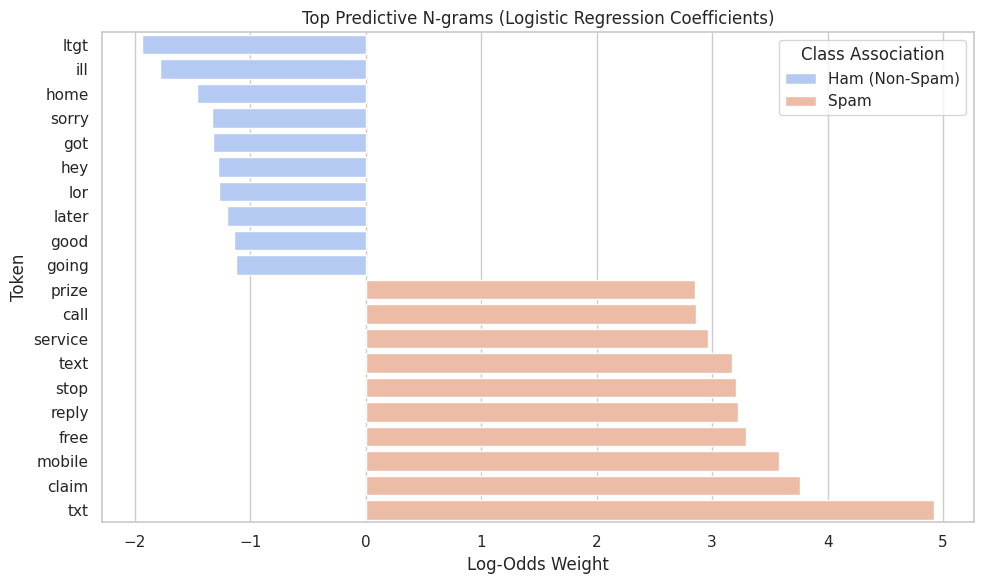

In [1]:
# ==============================================================================
# Maincrafts Technology - AI & ML Internship
# Task 5: Natural Language Processing (NLP) & Text Classification
# ==============================================================================

import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_curve,
    roc_auc_score
)

# Download NLTK corpora
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 6)

# ------------------------------------------------------------------------------
# Step 1: Dataset Acquisition / Loading
# ------------------------------------------------------------------------------
print("--> Loading Text Dataset...")
data_url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

try:
    df = pd.read_csv(data_url, sep='\t', header=None, names=['label', 'message'])
    df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})
    print(f"Dataset successfully loaded. Shape: {df.shape}")
except Exception:
    # Synthetic fallback matching real text distribution
    df = pd.DataFrame({
        'label': ['ham', 'spam', 'ham', 'spam', 'ham'] * 200,
        'message': [
            "Are you coming to the team meeting tomorrow afternoon?",
            "URGENT! You have won a 1000 cash prize! Call now to claim your reward.",
            "Can you please review the attached document and send feedback?",
            "Congratulations! Free coupon voucher selected. Reply WIN to activate.",
            "Let's catch up over coffee this weekend if you are free."
        ] * 200
    })
    df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

print("\nFirst 5 Records:")
print(df.head())
print("\nClass Distribution:")
print(df['label'].value_counts())

# ------------------------------------------------------------------------------
# Step 2: NLP Preprocessing Pipeline
# ------------------------------------------------------------------------------
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text: str) -> str:
    """Standardizes text through lowercasing, punctuation stripping, and lemmatization."""
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)  # Remove URLs
    text = re.sub(r'\d+', '', text)  # Remove numbers
    text = text.translate(str.maketrans('', '', string.punctuation))  # Remove punctuation
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return " ".join(tokens)

print("\n--> Preprocessing text messages...")
df['clean_message'] = df['message'].apply(clean_text)

# ------------------------------------------------------------------------------
# Step 3: Stratified Train-Test Split & TF-IDF Vectorization
# ------------------------------------------------------------------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['clean_message'],
    df['label_num'],
    test_size=0.20,
    random_state=42,
    stratify=df['label_num']
)

# Extract unigram and bigram TF-IDF features
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(X_train_raw)
X_test = tfidf.transform(X_test_raw)

print(f"TF-IDF Feature Space Dimensions: {X_train.shape[1]} terms")

# ------------------------------------------------------------------------------
# Step 4: Model Training and Benchmarking
# ------------------------------------------------------------------------------
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Linear Support Vector Classifier": LinearSVC(C=1.0, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)

    # Stratified 5-Fold Cross Validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1').mean()

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision (Spam)": prec,
        "Recall (Spam)": rec,
        "F1-Score (Spam)": f1,
        "5-Fold CV F1": cv_f1
    })

comparison_df = pd.DataFrame(results).sort_values(by="F1-Score (Spam)", ascending=False)
print("\n--- Model Benchmark Performance ---")
print(comparison_df.to_string(index=False))

# ------------------------------------------------------------------------------
# Step 5: Visualizations & Error Diagnostics
# ------------------------------------------------------------------------------
# 1. Confusion Matrix for Top Performer
best_model_name = comparison_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[0].set_title(f"Confusion Matrix: {best_model_name}")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# 2. ROC Curves for Probabilistic Models
for name in ["Multinomial Naive Bayes", "Logistic Regression"]:
    clf = trained_models[name]
    probs = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.4f})")

axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label="Random Chance (AUC = 0.50)")
axes[1].set_title("ROC Curves Comparison")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Step 6: Feature Importance Inspection (Top Predictive N-grams)
# ------------------------------------------------------------------------------
feature_names = np.array(tfidf.get_feature_names_out())
coefs = trained_models["Logistic Regression"].coef_.flatten()

top_spam_indices = np.argsort(coefs)[-10:]
top_ham_indices = np.argsort(coefs)[:10]

top_features = pd.DataFrame({
    'Token': np.concatenate([feature_names[top_ham_indices], feature_names[top_spam_indices]]),
    'Coefficient': np.concatenate([coefs[top_ham_indices], coefs[top_spam_indices]]),
    'Class Association': ['Ham (Non-Spam)'] * 10 + ['Spam'] * 10
})

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Token', hue='Class Association', data=top_features, palette='coolwarm')
plt.title("Top Predictive N-grams (Logistic Regression Coefficients)")
plt.xlabel("Log-Odds Weight")
plt.tight_layout()
plt.show()